# **Static Obstacle Avoidance** 🚧🏎️

---

**What this notebook does:** Now that we have successfully deployed a racing policy on our car, lets train a policy that reacts to obstacles with
using our lidar in real time, instead of memorizing one safe line around one fixed obstacle for a head-to-head racing scenerio.

**How:** every episode, we bake 1-3 rectangular obstacles — sized close to our
own car — into the track's occupancy grid, at a new random position, size, and
orientation. Because the obstacle becomes part of the same grid the lidar
already scans against, nothing about our lidar or collision code has to
change — the car just sees "wall" exactly where we painted it. Since the
obstacle is never in the same place twice, the only way the policy can survive
is to genuinely read the lidar and react.

📌 In this notebook we shall us the same PPO algorithm as Learn to Race — only the environment
and rewards change.

---


## 📋 How This Works

We build a pool of maps, each with a few obstacles baked directly into the
track image, and hand the car a different one every episode:

1. **Load the track's occupancy grid** (the same grid the lidar already scans against).
2. **Paint 1-3 random rectangles onto a copy of it** — random position along
   the centerline, random size close to our car's own footprint, random
   orientation.
3. **Save many such variants** ahead of time (a "pool"), instead of just one.
4. **Pick a fresh, unseen variant every `reset()`** during training.

Because the obstacle lives in the same grid as the walls, our existing
lidar/collision pipeline needs **zero changes** — the gym just treats a
painted obstacle like a wall.


<p align="left">
  <img src="https://raw.githubusercontent.com/dhyeyshah28/RL_for_Roboracer/main/assets/images/static_obs.gif" width="530"/>
</p>


---


---

# **Section 1 — Setup** 🔧

In [ ]:
# ── Install all dependencies ──────────────────────────────────────────────────
# f1tenth_gym: the race car simulator (dev-humble branch = latest stable)
!pip install -q git+https://github.com/f1tenth/f1tenth_gym.git@dev-humble

# stable-baselines3: we use only its VecEnv utilities (parallel envs, reward
# normalization) for running rollouts — the PPO algorithm itself is ours
!pip install -q stable-baselines3[extra]

# wandb: experiment tracking — we will log metrics here in real time
!pip install -q wandb

print("Installation complete!")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 258.0/258.0 kB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 953.9/953.9 kB 42.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 68.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 71.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 67.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.0/86.0 MB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 301.7/301.7 kB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 3.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gymnasium>=1.0.0, but you have gy

## 1.2 Verify Imports 📦

In [ ]:
# ── Verify everything imports correctly ───────────────────────────────────────

import os
import yaml
import warnings
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# This gym reuses observation buffers for speed, which gymnasium's passive
# checker flags on every reset/step — harmless here, so we quiet it (plus a
# jupyter_client deprecation notice neither we nor the gym control).
warnings.filterwarnings("ignore", message=".*share an object.*")
warnings.filterwarnings("ignore", category=DeprecationWarning, module="jupyter_client")

import gymnasium as gym
import torch
import stable_baselines3
import wandb
import f1tenth_gym
from f1tenth_gym.envs.track import Track

print(f"PyTorch:          {torch.__version__}")
print(f"CUDA available:   {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU:              {torch.cuda.get_device_name(0)}")
print(f"Stable Baselines: {stable_baselines3.__version__}")
print(f"Gymnasium:        {gym.__version__}")
print()
print("All good — let's start training!")


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PyTorch:          2.11.0+cpu
CUDA available:   False
Stable Baselines: 2.9.0
Gymnasium:        0.29.1

All good — let's start training!


## 1.3 Pre-Cache the Track Map 🗺️

In [ ]:
# ── Pre-cache the track map ───────────────────────────────────────────────────
Track.from_track_name('Spielberg')
print("Spielberg track cached — ready to train!")

Extracting Files for: Spielberg
Spielberg track cached — ready to train!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---

# **Section 2 — Generating Randomized Obstacle Maps** 🧱

## 2.1 World Coordinates ↔ Pixel Coordinates 📐

The track map is an image: black pixels are walls/obstacles, white pixels are
free space. A YAML file next to it tells us the `resolution` (metres per
pixel) and the `origin` (where the image's bottom-left corner sits in the
world). To paint an obstacle at a real-world point, we first need to turn
that world point into a pixel.

One consideration: image row 0 is the **top** of the image, but world-$y$ increases
**upward** — the opposite direction. So the row index needs a flip:

$$\text{col} = \frac{x - x_{\text{origin}}}{\text{resolution}} \qquad
\text{row} = H - 1 - \frac{y - y_{\text{origin}}}{\text{resolution}}$$


## 2.2 The Generation Strategy 🧩

For every variant we want to create, we repeat four simple steps:

1. **Pick a spot** — a random point along the track centerline (so the
   obstacle sits somewhere the car would otherwise drive), skipping the area
   right at the spawn point so the car isn't dropped on top of an obstacle.
2. **Pick a size and count** — 1 to 3 obstacles, each a rectangle close to our
   own car's footprint (car is 0.31m × 0.58m), with some random variation in
   size and a random rotation so it isn't always axis-aligned.
3. **Paint it** — convert the obstacle's world position to pixels and draw a
   filled rectangle into a **copy** of the base map.
4. **Save it** — write the new image + a matching YAML under a new map name.

We repeat this many times to build a **pool of variants**, so training can
hand out a fresh, never-before-seen layout at every episode.

<p align="left">
  <img src="https://raw.githubusercontent.com/dhyeyshah28/RL_for_Roboracer/main/assets/images/static_obs.png" width="430"/>
</p>


## 2.3 Generator Functions ⚙️

Loads the base map through the gym itself and reads the real occupancy grid straight off the resulting
`Track` object — no guessing at file paths.


In [ ]:
# ── Obstacle Map Generator ──────────────────────────────────────────────────────
# The base map's image is NOT a real file on disk in this gym build
# — but Track.occupancy_map gives us the
# actual grid data directly, already loaded. We paint obstacles onto that,
# then save our OWN new file.



BASE_MAP_NAME     = "Spielberg"     # track to add obstacles to
NUM_VARIANTS      = 40              # size of the randomized obstacle-map pool
MIN_OBSTACLES     = 1
MAX_OBSTACLES     = 3
OBSTACLE_RADIUS_M = (0.2, 0.5)      # metres — random radius per obstacle


def _get_base_map_info(map_name):
    """
    Loads map_name through the gym exactly as training does, and reads the
    metadata (spec.to_dict()) and the ALREADY-LOADED occupancy grid array
    directly off the Track object.
    """
    from f1tenth_gym.envs.env_config import EnvConfig
    tmp_env = gym.make("f1tenth_gym:f1tenth-v0", config=EnvConfig(map_name=map_name, num_agents=1),
                        disable_env_checker=True)  # this gym reuses obs buffers by design — the checker just warns about that, so skip it
    try:
        track = tmp_env.unwrapped.track
        waypoints = np.column_stack([track.centerline.xs, track.centerline.ys])
        meta = track.spec.to_dict()
        occ  = np.array(track.occupancy_map)
        print(f"[DEBUG] occupancy_map: shape={occ.shape}, dtype={occ.dtype}, "
              f"min={occ.min()}, max={occ.max()}")
        return meta, waypoints, occ
    finally:
        tmp_env.close()


def _world_to_pixel(x, y, resolution, origin, height):
    """
    World (x, y) metres -> pixel (col, row).
    Confirmed empirically (overlay diagnostic) for this gym's occupancy_map
    array: NO row-flip — row 0 already corresponds to the low-y edge, unlike
    the standard ROS map_server image convention this was originally written
    for.
    """
    col = int((x - origin[0]) / resolution)
    row = int((y - origin[1]) / resolution)
    return col, row


def _sample_centerline_point(waypoints, track_length_frac_range=(0.15, 0.95)):
    """Pick a random point along the centerline, skipping the region near spawn."""
    n = len(waypoints)
    lo = int(track_length_frac_range[0] * n)
    hi = int(track_length_frac_range[1] * n)
    idx = np.random.randint(lo, hi)
    return waypoints[idx]


def generate_obstacle_map(meta, occ_array, waypoints, variant_id):
    """
    Paints 1-3 randomly placed, randomly sized circular obstacles directly
    onto a copy of the occupancy grid (numpy array — works regardless of
    whether it's boolean, 0/1, or 0/255), then saves the result as a real
    PNG + yaml pair in OUTPUT_DIR. Returns a map_name string (full path, no
    extension) for use with F1TenthObstacleWrapper.
    """
    resolution = float(meta["resolution"])
    origin     = meta["origin"]
    height, width = occ_array.shape

    occ = occ_array.copy()
    # Detect the grid's value convention at runtime rather than assuming one:
    # raw grayscale (0-255) uses a LOW value for occupied; a normalized/boolean
    # grid (max <= 1) uses a HIGH value (1 / True) for occupied.
    occupied_value = 0 if occ.max() > 1.5 else occ.dtype.type(1)

    yy, xx = np.ogrid[:height, :width]
    n_obstacles = np.random.randint(MIN_OBSTACLES, MAX_OBSTACLES + 1)
    for _ in range(n_obstacles):
        # TODO: implement Section 2.2's steps 1-3 for ONE obstacle:
        #   1. _sample_centerline_point(waypoints)             -> wx, wy
        #   2. pick a random radius from OBSTACLE_RADIUS_M      -> radius_m
        #   3. _world_to_pixel(...) -> cx, cy ; convert radius_m to r_px
        #   4. build a circular boolean mask and set occ[mask] = occupied_value
        #      (hint: (xx - cx)**2 + (yy - cy)**2 <= r_px**2)
        # YOUR CODE HERE
        pass

    # Convert to a standard 0-255 grayscale PNG regardless of the grid's
    # original dtype/range.
    occ_float = occ.astype(np.float32)
    if occ_float.max() <= 1.5:
        occ_float = occ_float * 255.0
    occ_uint8 = np.clip(occ_float, 0, 255).astype(np.uint8)

    # FLIP BEFORE SAVING. Track.occupancy_map is stored ALREADY flipped
    # top-to-bottom (the gym does FLIP_TOP_BOTTOM when it loads a PNG), and
    # Track.from_track_path() flips AGAIN when it loads ours.
    img_out = Image.fromarray(np.flipud(occ_uint8), mode="L")

    new_name      = f"{BASE_MAP_NAME}_obs{variant_id}"
    new_img_path  = OUTPUT_DIR / f"{new_name}.png"
    # Track.from_track_path() does: Path(map_name).parent / f"{Path(map_name).stem}_map.yaml"
    # so the yaml MUST be named "<name>_map.yaml", while the returned map_name
    # itself stays WITHOUT that suffix (so .stem correctly equals new_name).
    new_yaml_path = OUTPUT_DIR / f"{new_name}_map.yaml"
    new_cl_path   = OUTPUT_DIR / f"{new_name}_centerline.csv"

    img_out.save(new_img_path)

    # NO "name" KEY IN THE YAML. Track.load_spec() calls
    # TrackSpec(name=<stem>, **yaml_contents); a "name:" key inside the yaml
    # makes that "got multiple values for keyword argument 'name'".
    # Also writing an explicit, minimal dict instead of copying spec.to_dict()
    # wholesale, so nothing unexpected leaks into the file.
    new_meta = {
        "image":           new_img_path.name,
        "resolution":      float(meta["resolution"]),
        "origin":          [float(v) for v in meta["origin"]],
        "negate":          int(meta.get("negate", 0)),
        "occupied_thresh": float(meta.get("occupied_thresh", 0.45)),
        "free_thresh":     float(meta.get("free_thresh", 0.196)),
    }
    with open(new_yaml_path, "w") as f:
        yaml.safe_dump(new_meta, f)

    # WRITE A CENTERLINE CSV NEXT TO THE MAP. Track.from_track_path()
    # raises ValueError("Please provide a centerline/raceline.") if neither
    # <name>_centerline.csv nor <name>_raceline.csv exists. The env needs the
    # centerline for frenet_pose (our progress reward). Same track, so we
    # reuse the base track's centerline points; only x_m, y_m are required.
    np.savetxt(new_cl_path, np.asarray(waypoints, dtype=np.float64),
               delimiter=",", header="x_m,y_m", comments="")

    return str(OUTPUT_DIR / new_name)   # NOT new_yaml_path — must match "<name>_map.yaml" pattern


OUTPUT_DIR = Path("/content/obstacle_maps")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Obstacle map generator defined.")


Obstacle map generator defined.


## 2.4 Pre-Generate the Obstacle Map Pool 🏗️

Run this once — it reads the base map's occupancy grid directly from memory, then saves `NUM_VARIANTS` randomized obstacle maps as real files we control.

A sanity check at the end confirms the first variant's files genuinely exist on disk before anything downstream tries to load them.

In [ ]:
# ── Pre-generate the pool of randomized obstacle maps ──────────────────────────
base_meta, waypoints, base_occ = _get_base_map_info(BASE_MAP_NAME)
print(f"Loaded {len(waypoints)} centerline waypoints from {BASE_MAP_NAME}")
print(f"Saving generated variants to: {OUTPUT_DIR}")

OBSTACLE_MAP_POOL = []
for i in range(NUM_VARIANTS):
    name = generate_obstacle_map(base_meta, base_occ, waypoints, variant_id=i)
    OBSTACLE_MAP_POOL.append(name)

print(f"Generated {len(OBSTACLE_MAP_POOL)} obstacle map variants:")
print(f"  {OBSTACLE_MAP_POOL[:2]} ... {OBSTACLE_MAP_POOL[-2:]}")

# Quick sanity check — confirm the FIRST variant's files genuinely exist on disk,
# using the SAME "<name>_map.yaml" pattern Track.from_track_path() expects.
_check_img  = Path(OBSTACLE_MAP_POOL[0] + ".png")
_check_yaml = Path(OBSTACLE_MAP_POOL[0] + "_map.yaml")
print(f"First variant image exists: {_check_img.exists()}  ({_check_img})")
print(f"First variant yaml exists:  {_check_yaml.exists()}  ({_check_yaml})")

_check_cl = Path(OBSTACLE_MAP_POOL[0] + "_centerline.csv")
print(f"First variant centerline exists: {_check_cl.exists()}  ({_check_cl})")

# End-to-end load through the SAME code path the workers use. If anything about
# the generated files is wrong, it fails HERE with a readable error, not later
# inside a SubprocVecEnv worker as a generic ConnectionResetError.
from f1tenth_gym.envs.track import Track as _Track
_t = _Track.from_track_path(Path(OBSTACLE_MAP_POOL[0]))
_same = int((np.array(_t.occupancy_map) != base_occ).sum())
print(f"Variant 0 loads OK. Pixels differing from the base map (should be ~ the obstacle area, "
      f"NOT most of the map): {_same:,} of {base_occ.size:,}")
assert _same < 0.05 * base_occ.size, "Reloaded map differs a lot from base map — orientation bug"


[DEBUG] occupancy_map: shape=(2000, 2000), dtype=float32, min=0.0, max=255.0
Loaded 865 centerline waypoints from Spielberg
Saving generated variants to: /content/obstacle_maps


/tmp/ipykernel_1884/2218012854.py:97: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img_out = Image.fromarray(np.flipud(occ_uint8), mode="L")
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Generated 40 obstacle map variants:
  ['/content/obstacle_maps/Spielberg_obs0', '/content/obstacle_maps/Spielberg_obs1'] ... ['/content/obstacle_maps/Spielberg_obs38', '/content/obstacle_maps/Spielberg_obs39']
First variant image exists: True  (/content/obstacle_maps/Spielberg_obs0.png)
First variant yaml exists:  True  (/content/obstacle_maps/Spielberg_obs0_map.yaml)
First variant centerline exists: True  (/content/obstacle_maps/Spielberg_obs0_centerline.csv)
Variant 0 loads OK. Pixels differing from the base map (should be ~ the obstacle area, NOT most of the map): 230 of 4,000,000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Sanity Check — World-to-Pixel Transform ✅

Confirmed correct via overlay comparison: this gym's `occupancy_map` array does **not** need a row-flip (row 0 already corresponds to the low-y edge). `_world_to_pixel()` reflects this. Run this cell any time to re-confirm the red dots trace the track we load exactly before trusting generated obstacle variants.

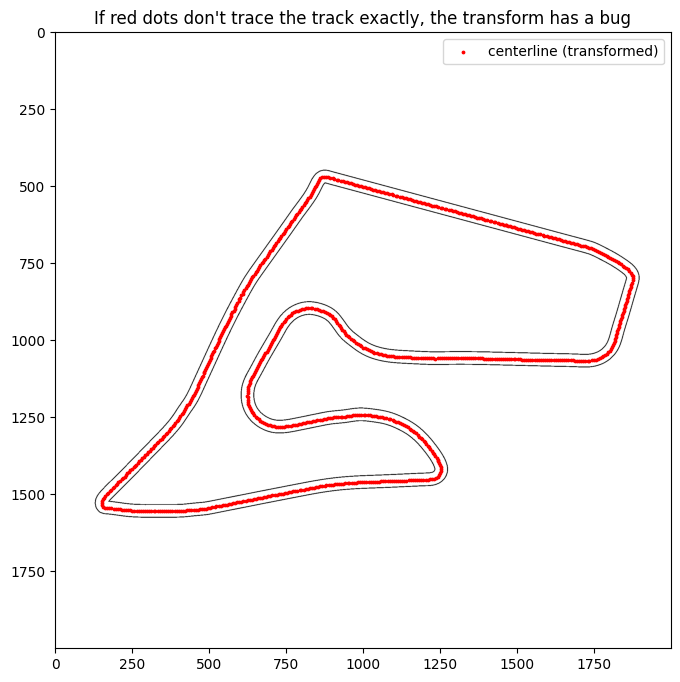

occ shape (height, width): (2000, 2000)
resolution: 0.05796
origin: [-84.85359914210505, -36.30299725862132, 0.0]
waypoint x range: -76.09 to 23.89
waypoint y range: -9.12 to 53.81
expected width from x-range:  1725 px
expected height from y-range: 1086 px


In [ ]:
# ── DIAGNOSTIC: overlay the transformed centerline on the occupancy grid ──────
# If the world-to-pixel conversion is correct, the red dots should trace
# exactly along the track shown in gray. Any offset, scale mismatch, or
# flip will show up immediately as red dots drifting away from the track.
height, width = base_occ.shape
resolution = float(base_meta["resolution"])
origin     = base_meta["origin"]

pixel_pts = np.array([_world_to_pixel(x, y, resolution, origin, height) for x, y in waypoints])

plt.figure(figsize=(10, 8))
plt.imshow(base_occ, cmap='gray')
plt.scatter(pixel_pts[:, 0], pixel_pts[:, 1], s=3, c='red', label='centerline (transformed)')
plt.legend()
plt.title("If red dots don't trace the track exactly, the transform has a bug")
plt.show()

print(f"occ shape (height, width): {base_occ.shape}")
print(f"resolution: {resolution}")
print(f"origin: {origin}")
print(f"waypoint x range: {waypoints[:,0].min():.2f} to {waypoints[:,0].max():.2f}")
print(f"waypoint y range: {waypoints[:,1].min():.2f} to {waypoints[:,1].max():.2f}")
print(f"expected width from x-range:  {(waypoints[:,0].max()-waypoints[:,0].min())/resolution:.0f} px")
print(f"expected height from y-range: {(waypoints[:,1].max()-waypoints[:,1].min())/resolution:.0f} px")


## 2.5 Sanity Check — Visualize a Few Variants 👀

Before training on these, look at a few to confirm the obstacles landed on
the track (not off-map or overlapping the spawn region).

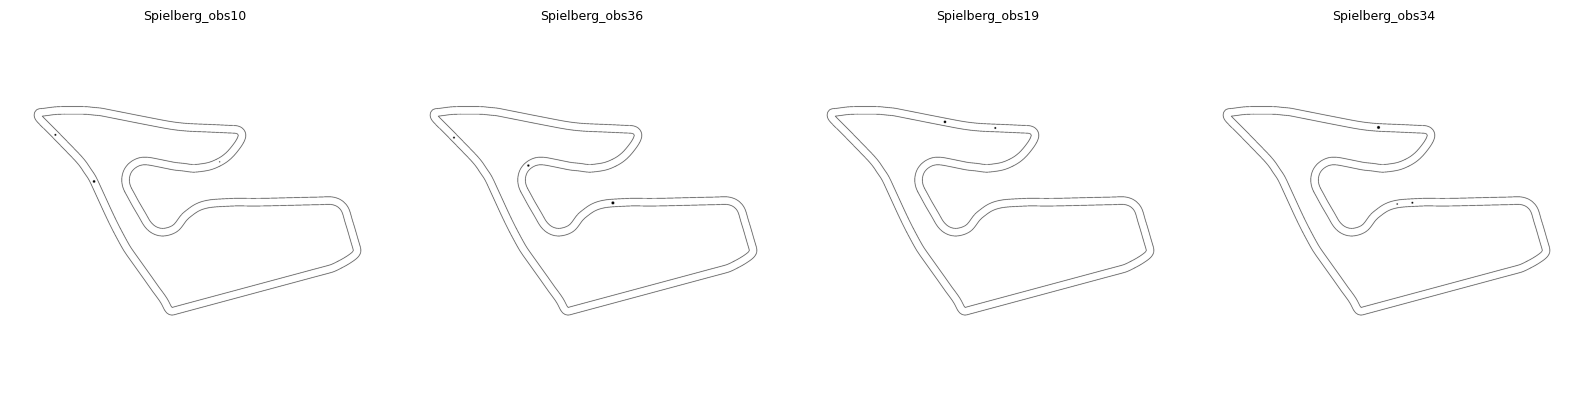

If the black blobs look like they're sitting on the track (not off in
empty space or right on top of the start line), the generator is working.


In [ ]:
# ── Visualize a few generated variants ──────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
sample_variants = np.random.choice(OBSTACLE_MAP_POOL, size=4, replace=False)
for ax, name in zip(axes, sample_variants):
    img_path = Path(name + ".png")   # variants are saved as "<map_name>.png"
    img = Image.open(img_path)
    ax.imshow(img, cmap='gray')
    ax.set_title(Path(name).name, fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()
print("If the black blobs look like they're sitting on the track (not off in")
print("empty space or right on top of the start line), the generator is working.")


---

# **Section 3 — Reward for Obstacle Avoidance** 🎯

We reuse two reward terms from Learn to Race as-is, and **drop one on purpose**:

- **Keep: progress + speed bonus** — same as always
- **Keep: wall/obstacle proximity penalty** — the obstacle lives in the same
  occupancy grid as the walls, so this term already discourages hitting it,
  with no new code needed
- **Keep (light touch): steering smoothness** — just enough to avoid jittery
  steering, without fighting the sharp swerves genuinely needed to dodge something
- **Drop: centerline lateral-error penalty** — this term punishes leaving the
  racing line, which is exactly what the car must do to avoid an obstacle
  sitting on that line. Keeping it would make the reward fight itself.

---


$$r_t = 10\,\Delta_{\text{progress}} + 0.03\,\tfrac{v}{v_{\max}} - 0.02\,|\Delta\theta| - 0.1\max(0,\ 0.5 - d_{\min}) - 30\cdot\mathbb{1}[\text{collision}]$$

---


---

# **Section 4 — The Obstacle Avoidance Wrapper** 🧩

We will also be using the same observation and action space as the prior modules. The only structural difference:
**every `reset()` builds (or reuses from a cache) an env pointed at a randomly
chosen obstacle-map variant.**

> **📌 Performance note:** each built simulator holds a full copy of the map
> in RAM. Caching every variant in every worker would exhaust memory
> (workers get killed → `BrokenPipeError`), so each worker keeps only the
> `MAX_CACHED_ENVS` most recently used simulators (LRU) and rebuilds others on
> demand (~0.3s).


In [ ]:
# ── F1TenthObstacleWrapper ──────────────────────────────────────────────────────
# A fresh, randomly-chosen obstacle map variant is loaded at EVERY reset() —
# the car never sees the same obstacle layout twice, forcing it to react to
# the lidar rather than memorize a fixed detour.

STEER_SMOOTH_COEF   = 0.02      # light touch — don't fight necessary swerves
WALL_PROX_COEF      = 0.1
WALL_PROX_THRESHOLD = 0.5

# Each cached simulator holds a full copy of the map (~16 bytes/pixel — tens to
# hundreds of MB on a big track). Caching ALL variants in EVERY worker made RAM
# grow until Linux killed a worker (BrokenPipeError mid-training). Keep only a
# few alive per worker; a cache miss costs ~0.3 s to rebuild, which is
# negligible next to an episode of hundreds of steps.

MAX_CACHED_ENVS     = 3


import gc
from collections import OrderedDict


class F1TenthObstacleWrapper(gym.Env):
    """
    Observation (110-dim, all in [0,1]) and action space — identical to
    Learn to Drive / Learn to Race. Only the map (via reset) and reward differ.
    """

    def __init__(self, obstacle_map_pool, num_beams=108, render_mode=None):
        super().__init__()
        self.obstacle_map_pool = obstacle_map_pool
        self.render_mode       = render_mode
        self.num_beams         = num_beams
        self.lidar_clip        = 10.0
        self.max_speed         = 6.0
        self.min_speed         = 1.5
        self.max_steps         = 10000
        self.current_step      = 0

        self.observation_space = gym.spaces.Box(
            low=0.0, high=1.0, shape=(num_beams + 2,), dtype=np.float32
        )
        self.action_space = gym.spaces.Box(
            low=-1.0, high=1.0, shape=(2,), dtype=np.float32
        )

        self.env = None   # points at whichever cached env is active this episode
        self.max_steer  = 0.4189   # gym default; refreshed once self.env exists
        self._env_cache = OrderedDict()   # map_name -> built env, LRU-capped at
                                          # MAX_CACHED_ENVS so memory stays flat

    # ----------------------------------------------------------

    def _build_env(self, map_name):
        from f1tenth_gym.envs.env_config import (
            EnvConfig, SimulationConfig, ObservationConfig, ResetConfig,
        )
        from f1tenth_gym.envs.lidar.config import LiDARConfig
        from f1tenth_gym.envs.observation import ObservationType
        from f1tenth_gym.envs.reset import ResetStrategy
        from f1tenth_gym.envs.integrators import IntegratorType
        from f1tenth_gym.envs.dynamic_models import DynamicModel

        env_config = EnvConfig(
            map_name=map_name,
            num_agents=1,
            simulation_config=SimulationConfig(
                timestep=0.01,
                integrator=IntegratorType.RK4,
                dynamics_model=DynamicModel.ST,
                max_laps=5,
            ),
            observation_config=ObservationConfig(type=ObservationType.DIRECT),
            lidar_config=LiDARConfig(num_beams=self.num_beams, range_max=10.0, noise_std=0.0),
            reset_config=ResetConfig(strategy=ResetStrategy.RL_RANDOM_STATIC),
            render_enabled=(self.render_mode is not None),
        )
        env = gym.make("f1tenth_gym:f1tenth-v0", config=env_config, render_mode=self.render_mode,
                        disable_env_checker=True)  # same reused-buffer warning as above, silenced here too
        self.max_steer = float(env.action_space.high[0][0])
        try:
            self.track_length = env.unwrapped.track.centerline.length
        except Exception:
            self.track_length = None
        return env

    def _get_progress(self, raw_obs):
        try:
            frenet = raw_obs["agent_0"].get("frenet_pose", None)
            if frenet is not None and self.track_length:
                s = float(frenet[0])
                return (s % self.track_length) / self.track_length
        except Exception:
            pass
        return 0.0   # no waypoint fallback needed — frenet is always available here

    def _process_obs(self, raw_obs):
        agent = raw_obs["agent_0"]
        scan  = np.array(agent["scan"], dtype=np.float32) / self.lidar_clip
        state = agent["std_state"]
        speed_norm = np.clip(float(state[3]) / self.max_speed, 0.0, 1.0)
        steer_norm = np.clip(
            (float(state[2]) + self.max_steer) / (2 * self.max_steer), 0.0, 1.0
        )
        return np.concatenate([
            scan.astype(np.float32),
            np.array([speed_norm, steer_norm], dtype=np.float32)
        ])

    def _scale_action(self, action):
        steer = float(action[0]) * self.max_steer
        speed = (float(action[1]) + 1.0) * 0.5 * (self.max_speed - self.min_speed) + self.min_speed
        return np.array([[steer, speed]], dtype=np.float32)

    # ----------------------------------------------------------

    def reset(self, seed=None, options=None):
        # ── Pick a random obstacle layout, building it once then reusing it ────
        map_name = str(np.random.choice(self.obstacle_map_pool))
        if map_name in self._env_cache:
            self._env_cache.move_to_end(map_name)          # mark most-recently used
        else:
            while len(self._env_cache) >= MAX_CACHED_ENVS:  # evict least-recently used
                _, old_env = self._env_cache.popitem(last=False)
                old_env.close()
                del old_env
                gc.collect()
            self._env_cache[map_name] = self._build_env(map_name)
        self.env = self._env_cache[map_name]
        self.max_steer = float(self.env.action_space.high[0][0])
        try:
            self.track_length = self.env.unwrapped.track.centerline.length
        except Exception:
            self.track_length = None

        raw_obs, info      = self.env.reset(seed=seed)
        self.current_step  = 0
        self.prev_progress = self._get_progress(raw_obs)

        state = raw_obs["agent_0"]["std_state"]
        self.prev_physical_steer = float(state[2])

        return self._process_obs(raw_obs), info

    def step(self, action):
        physical_action = self._scale_action(action)
        raw_obs, _, done, truncated, info = self.env.step(physical_action)
        self.current_step += 1

        state     = raw_obs["agent_0"]["std_state"]
        speed     = float(state[3])
        collision = bool(raw_obs["agent_0"].get("collision", False))
        scan_raw  = raw_obs["agent_0"]["scan"]
        min_scan  = float(np.min(scan_raw))

        progress       = self._get_progress(raw_obs)
        delta_progress = progress - self.prev_progress
        if delta_progress < -0.5:
            delta_progress += 1.0

        # TODO: implement the reward from Section 3:
        #   r_t = 10*delta_progress + 0.03*(v/v_max) - 0.02*|steer_delta|
        #         - 0.1*max(0, 0.5 - min_scan) - 30 * collision
        # 1. progress + speed bonus
        # 2. light steering-smoothness penalty (update self.prev_physical_steer!)
        # 3. wall/obstacle proximity penalty when min_scan < WALL_PROX_THRESHOLD
        # 4. big negative reward + done=True on collision
        reward = 0.0
        physical_steer_now = float(state[2])
        self.prev_physical_steer = physical_steer_now
        # YOUR CODE HERE

        if self.current_step >= self.max_steps:
            truncated = True

        info["speed"]       = speed
        info["collision"]   = collision
        info["progress"]    = progress
        info["min_scan"]    = min_scan
        info["steer_delta"] = steer_delta

        # Stashed for diagnostics only (e.g. the video-recording cell) — doesn't
        # change anything about reward/termination, just exposes the raw numbers
        # so we can check from outside whether the car is really standing still.
        self.last_xy        = (float(state[0]), float(state[1]))
        self.last_speed     = speed
        self.last_collision = collision
        self.last_min_scan  = min_scan

        self.prev_progress = progress
        return self._process_obs(raw_obs), float(reward), done, truncated, info

    def render(self):
        return self.env.render()

    def close(self):
        for cached_env in self._env_cache.values():
            cached_env.close()


print("F1TenthObstacleWrapper defined — a new random obstacle layout every episode.")


F1TenthObstacleWrapper defined — a new random obstacle layout every episode.


### Diagnostic — Test the Wrapper in a Single Process 🔍

Run this BEFORE the main training cell. `SubprocVecEnv` (used when `NUM_ENVS > 1`) hides real exceptions from crashed worker processes behind a generic `ConnectionResetError` — this reproduces the same construction in the main process so any real error is fully visible.

> ⚠️ Do not skip this cell. If it prints `FAILED`, fix that first — the training cell will fail the same way.

In [ ]:
# ── DIAGNOSTIC: test F1TenthObstacleWrapper directly, single process ─────────

test_env = F1TenthObstacleWrapper(obstacle_map_pool=OBSTACLE_MAP_POOL)

for attempt in range(5):
    print(f"--- reset attempt {attempt+1} ---")
    try:
        obs, info = test_env.reset()
        print(f"  OK — obs shape: {obs.shape}, active map: {list(test_env._env_cache.keys())[-1]}")
    except Exception as e:
        print(f"  FAILED: {type(e).__name__}: {e}")
        import traceback
        traceback.print_exc()
        break

test_env.close()


--- reset attempt 1 ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  OK — obs shape: (110,), active map: /content/obstacle_maps/Spielberg_obs5
--- reset attempt 2 ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  OK — obs shape: (110,), active map: /content/obstacle_maps/Spielberg_obs17
--- reset attempt 3 ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  OK — obs shape: (110,), active map: /content/obstacle_maps/Spielberg_obs19
--- reset attempt 4 ---
  OK — obs shape: (110,), active map: /content/obstacle_maps/Spielberg_obs3
--- reset attempt 5 ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  OK — obs shape: (110,), active map: /content/obstacle_maps/Spielberg_obs14


---

# **Section 5 — PPO Algorithm (Unchanged)** 🧠

The network, GAE, and clipped loss are identical to Learn to Drive / Learn to
Race — only the environment changed.

In [ ]:
# ── Imports for from-scratch PPO ──────────────────────────────────────────────
import copy
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal

# Vectorized environment utilities — run several simulators in parallel and
# normalize rewards for stable gradients. The PPO algorithm itself is ours,
# built from scratch in the sections below.
from stable_baselines3.common.vec_env import (
    SubprocVecEnv, DummyVecEnv, VecMonitor, VecNormalize
)

print('PyTorch version:', torch.__version__)
print('Modules imported — we build PPO ourselves below.')


PyTorch version: 2.11.0+cpu
Modules imported — we build PPO ourselves below.


In [ ]:
# ── Actor-Critic Network ──────────────────────────────────────────────────────
# Two INDEPENDENT [64,64] MLPs — no shared trunk. Sharing weights between the
# actor and critic would let policy gradients and value gradients interfere
# with the same parameters, hurting both objectives. Orthogonal
# initialization with a small gain on the action head keeps initial actions
# near zero, which is important for early training stability.

def _orthogonal_init(layer, gain):
    nn.init.orthogonal_(layer.weight, gain=gain)
    nn.init.constant_(layer.bias, 0.0)

class ActorCritic(nn.Module):
    def __init__(self, obs_dim, act_dim, hidden=64):
        super().__init__()
        # Actor — fully independent MLP, own weights
        self.actor = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden),  nn.Tanh(),
        )
        self.actor_mean = nn.Linear(hidden, act_dim)

        # Critic — fully independent MLP, own weights (no sharing with the actor)
        self.critic_body = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden),  nn.Tanh(),
        )
        self.critic = nn.Linear(hidden, 1)

        # Learnable log standard deviation (state-independent)
        self.log_std = nn.Parameter(torch.zeros(act_dim))

        # Orthogonal init gains: sqrt(2) for hidden layers, 0.01 for the
        # action output (near-zero initial actions), 1.0 for the value output
        for layer in self.actor:
            if isinstance(layer, nn.Linear): _orthogonal_init(layer, gain=2 ** 0.5)
        for layer in self.critic_body:
            if isinstance(layer, nn.Linear): _orthogonal_init(layer, gain=2 ** 0.5)
        _orthogonal_init(self.actor_mean, gain=0.01)
        _orthogonal_init(self.critic, gain=1.0)

    def forward(self, obs):
        # ═══════════════════════════════════════════════════════════════
        # ✏️  TODO 5 — Actor-Critic Forward Pass
        # ═══════════════════════════════════════════════════════════════
        # Compute:
        #   mean       = self.actor_mean(self.actor(obs))
        #   value      = self.critic(self.critic_body(obs)).squeeze(-1)
        #   std        = self.log_std.exp()  (broadcast to mean's shape)
        #   dist       = Normal(mean, std)
        # Return: dist, value
        # ───────────────────────────────────────────────────────────────
        mean  = self.actor_mean(self.actor(obs))
        value = self.critic(self.critic_body(obs)).squeeze(-1)
        std   = self.log_std.exp().expand_as(mean)
        dist  = Normal(mean, std)
        return dist, value
        # ═══════════════════════════════════════════════════════════════

    @torch.no_grad()
    def act(self, obs, deterministic=False):
        """Sample an action (or take the mean if deterministic)."""
        dist, value = self.forward(obs)
        action = dist.mean if deterministic else dist.sample()
        log_prob = dist.log_prob(action).sum(-1)
        return action, log_prob, value


print('ActorCritic network defined (separate actor/critic MLPs, orthogonal init).')


ActorCritic network defined (separate actor/critic MLPs, orthogonal init).


## 5.1 Environment Builders 🏭

In [ ]:
# ── Environment factory ───────────────────────────────────────────────────────

def make_env(rank, seed=0):
    """Returns a function that creates one F1TenthObstacleWrapper instance.
    Every instance shares the same OBSTACLE_MAP_POOL but picks independently."""
    def _init():
        env = F1TenthObstacleWrapper(obstacle_map_pool=OBSTACLE_MAP_POOL)
        env.reset(seed=seed + rank)
        return env
    return _init


def make_training_env(num_envs):
    fns = [make_env(i) for i in range(num_envs)]
    env = DummyVecEnv(fns) if num_envs == 1 else SubprocVecEnv(fns)
    env = VecMonitor(env)
    env = VecNormalize(env, norm_obs=False, norm_reward=True, clip_reward=10.0, gamma=0.99)
    return env


def make_eval_env():
    env = DummyVecEnv([make_env(99)])
    env = VecMonitor(env)
    env = VecNormalize(env, norm_obs=False, norm_reward=True, clip_reward=10.0,
                       gamma=0.99, training=False)
    return env


print("Environment builders defined successfully.")


Environment builders defined successfully.


## 5.2 GAE — Generalized Advantage Estimation 📊

In [ ]:
# ── GAE — Generalized Advantage Estimation ────────────────────────────────────
def compute_gae(rewards, values, dones, last_value, gamma=0.99, lam=0.95):
    """
    rewards, values, dones : tensors of shape (T, N)  [T steps, N envs]
    last_value             : tensor (N,) — V(s_T) for bootstrapping
    Returns advantages and returns, both (T, N).
    """
    T, N = rewards.shape
    advantages = torch.zeros_like(rewards)

    # ═══════════════════════════════════════════════════════════════
    # ✏️  TODO 6 — Compute GAE Advantages
    # ═══════════════════════════════════════════════════════════════
    # Loop backwards from t = T-1 to 0:
    #   next_value = last_value if t == T-1 else values[t+1]
    #   next_nonterminal = 1.0 - dones[t]
    #   delta = rewards[t] + gamma * next_value * next_nonterminal - values[t]
    #   last_adv = delta + gamma * lam * next_nonterminal * last_adv
    #   advantages[t] = last_adv
    # ───────────────────────────────────────────────────────────────
    last_adv = torch.zeros(N, device=rewards.device)
    for t in reversed(range(T)):
        next_value = last_value if t == T - 1 else values[t + 1]
        next_nonterminal = 1.0 - dones[t]
        delta = rewards[t] + gamma * next_value * next_nonterminal - values[t]
        last_adv = delta + gamma * lam * next_nonterminal * last_adv
        advantages[t] = last_adv
    # ═══════════════════════════════════════════════════════════════

    returns = advantages + values
    return advantages, returns


print('compute_gae defined.')


compute_gae defined.


---

# **Section 6 — Training** 🏋️

## 6.1 Training Configuration ⚙️

In [ ]:
# ── Training configuration ────────────────────────────────────────────────────
NUM_ENVS    = 4             # Parallel environments (each keeps a small LRU cache of simulators)
TOTAL_STEPS = 1_000_000     # Total training steps
DEVICE      = "cuda"

print("Training config:")
print(f"  Base map:        {BASE_MAP_NAME}")
print(f"  Obstacle pool:   {len(OBSTACLE_MAP_POOL)} variants")
print(f"  Envs:            {NUM_ENVS}")
print(f"  Steps:           {TOTAL_STEPS:,}")
print(f"  Device:          {DEVICE}")


Training config:
  Base map:        Spielberg
  Obstacle pool:   40 variants
  Envs:            4
  Steps:           1,000,000
  Device:          cuda


## 6.2 WandB Login 🔑

In [ ]:
# ── WandB login ───────────────────────────────────────────────────────────────

# Choose option 1 or 2, then paste your WANDB_API key
wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
/usr/local/lib/python3.13/dist-packages/notebook/utils.py:280: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  return LooseVersion(v) >= LooseVersion(check)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 1


wandb: You chose 'Create a W&B account'
wandb: Create an account here: https://wandb.ai/authorize?signup=true&ref=models
wandb: After creating your account, create a new API key and store it securely.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: dhyey28 (kvirmani-university-of-pennsylvania) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


True

## 6.3 Training Dashboard 📈

In [ ]:
# ── Live Inline Training Plots ────────────────────────────────────────────────
import matplotlib.gridspec as gridspec
from IPython.display import clear_output

_live = {"steps": [], "rew": [], "collision": [], "speed": [], "scan": [], "loss": []}

def draw_live_plots(total_steps):
    if len(_live['steps']) < 2:
        return
    BG = '#0d1117'
    fig = plt.figure(figsize=(14, 6), facecolor=BG)
    gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.5, wspace=0.35)
    plots = [
        (gs[0,0], _live['rew'],       'ep_reward ↑',        '#00bcd4'),
        (gs[0,1], _live['collision'], 'collision_rate ↓',   '#f44336'),
        (gs[0,2], _live['speed'],     'avg_speed m/s ↑',    '#69ff47'),
        (gs[1,0], _live['scan'],      'avg_min_scan m ↑',   '#ff9800'),
        (gs[1,1], _live['loss'],      'total_loss',         '#e91e63'),
    ]
    for spec, data, title, color in plots:
        ax = fig.add_subplot(spec)
        ax.set_facecolor('#1a1a2e')
        valid = [(s, v) for s, v in zip(_live['steps'], data) if v is not None]
        if valid:
            xs, ys = zip(*valid)
            ax.plot(xs, ys, color=color, lw=2, marker='o', markersize=3)
            ax.fill_between(xs, ys, alpha=0.15, color=color)
            lo, hi = min(ys), max(ys); pad = (hi-lo)*0.1 or 0.1
            ax.set_ylim(lo-pad, hi+pad)
        ax.set_title(title, color='white', fontsize=9, pad=4)
        ax.set_xlabel('Steps', color='#888', fontsize=7)
        ax.tick_params(colors='#888', labelsize=7)
        for spine in ax.spines.values(): spine.set_edgecolor('#333')
    step = _live['steps'][-1]
    pct  = step / total_steps * 100
    wandb_url = wandb.run.url if wandb.run else 'not connected'
    fig.suptitle(f'PPO from Scratch — Obstacle Avoidance  |  Step {step:,} / {total_steps:,}  ({pct:.1f}%)'
                 f'   |   WandB → {wandb_url}',
                 color='white', fontsize=9, x=0.02, ha='left')
    clear_output(wait=True)
    plt.show()
    plt.close(fig)

print('Live plot helper defined.')


Live plot helper defined.


## 6.4 Train 🚀

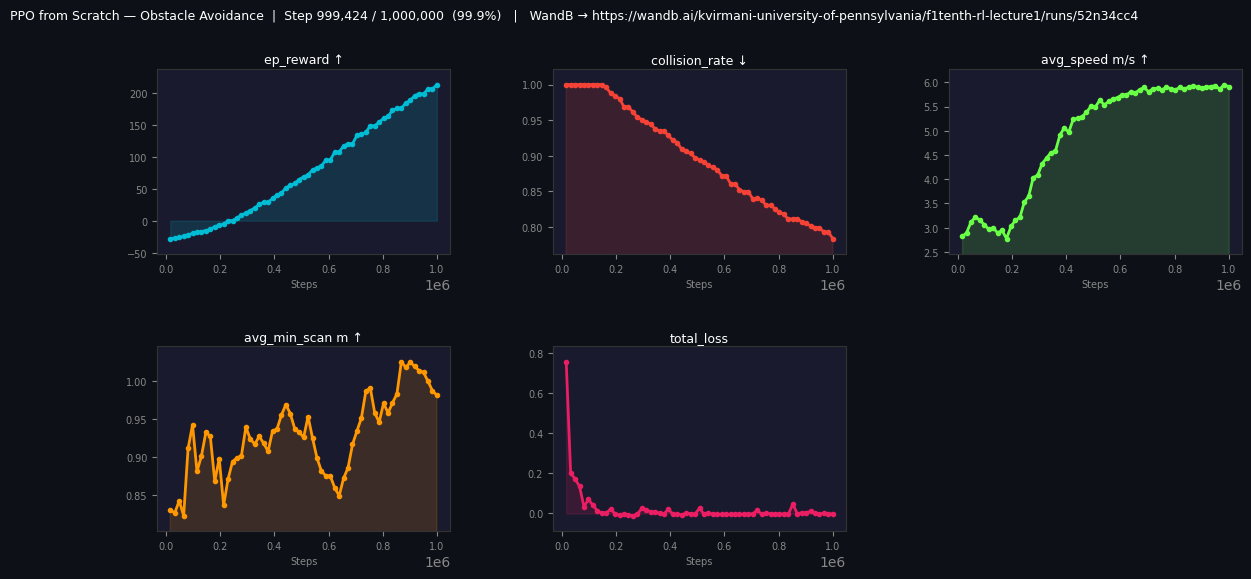

Update 61/61 | step 999,424 | episodes=351 | ep_rew_mean=213.2 | collision_rate=0.78 | loss=-0.0013

Saved → models_obstacle/ppo_scratch_obstacle.pt
Saved → models_obstacle/vecnormalize.pkl


eval/mean_ep_length,▁▂▅▁▇▅▆███▂▂▆▅▆
eval/mean_reward,▁▁▃▂▅▅▆▇██▄▄▇▆▇
global_step,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▃▃▃▃▃▄▄▅▅▅▆▆▇▇▇▇▇███
racing/avg_min_scan,▁▅▅▁▃▄▄▆▄▄▆▃▅▃▇▅▄▄▄▅▅▄▃▂▅▅▃▆▇▆▅▅▄▆█▇▆▆▇█
racing/avg_speed,▃▂▃▁▂▃▃▃▃▃▃▂▃▃▂▂▃▃▃▃▄▃▃▃▃▂▄▃▂▃▃▅▅▆▇▇████
racing/collision_rate,█████████████████████████▇▇▆▆▅▄▄▄▄▄▂▂▁▁▁
racing/episode_count,▁▁▂▂▂▂▃▃▃▃▃▃▃▄▄▄▅▅▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇███
rollout/ep_len_mean,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▃▃▃▄▄▄▅▆▇██
rollout/ep_len_std,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▃▅▆▆▇▇▇███▆
rollout/ep_rew_mean,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▃▅▅▆▇█
+6,...


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
#  PPO from Scratch — Obstacle Avoidance Training (Run This Single Cell)
# ══════════════════════════════════════════════════════════════════════════════
# Identical PPO algorithm to Learn to Drive / Learn to Race. Only the
# environment (randomized obstacle maps) and reward (no lateral-error term)
# differ. See those notebooks for full metric-definition notes.
# ──────────────────────────────────────────────────────────────────────────────
from collections import deque

N_STEPS       = 4096
N_EPOCHS      = 10
MINIBATCH     = 256
GAMMA         = 0.99
GAE_LAMBDA    = 0.95
CLIP_EPS      = 0.2
ENT_COEF      = 0.001
VF_COEF       = 0.5
LR            = 3e-4
MAX_GRAD      = 0.5
EVAL_FREQ     = 50_000
EVAL_EPISODES = 5

torch.manual_seed(42)
np.random.seed(42)

run = wandb.init(
    project = 'f1tenth-rl-lecture1',
    name    = f'ppo_scratch_obstacle_{BASE_MAP_NAME}_{TOTAL_STEPS//1000}k',
    config  = dict(n_steps=N_STEPS, n_epochs=N_EPOCHS, gamma=GAMMA,
                   gae_lambda=GAE_LAMBDA, clip_eps=CLIP_EPS, ent_coef=ENT_COEF,
                   lr=LR, base_map=BASE_MAP_NAME, num_envs=NUM_ENVS,
                   num_obstacle_variants=len(OBSTACLE_MAP_POOL)),
)
wandb.define_metric('global_step')
wandb.define_metric('*', step_metric='global_step')
print(f'🔗 WandB → {run.url}\n')

train_env = make_training_env(NUM_ENVS)
eval_env  = make_eval_env()
obs_dim   = train_env.observation_space.shape[0]
act_dim   = train_env.action_space.shape[0]

device = torch.device(DEVICE if torch.cuda.is_available() else 'cpu')
net    = ActorCritic(obs_dim, act_dim).to(device)
opt    = optim.Adam(net.parameters(), lr=LR, eps=1e-5)
print(net)
print(f'Parameters: {sum(p.numel() for p in net.parameters()):,}\n')

episode_count    = 0
total_collisions = 0

cur_rew  = np.zeros(NUM_ENVS)
cur_spd  = [[] for _ in range(NUM_ENVS)]
cur_scan = [[] for _ in range(NUM_ENVS)]
cur_col  = np.zeros(NUM_ENVS, dtype=bool)
cur_len  = np.zeros(NUM_ENVS, dtype=int)

ep_rew_window = deque(maxlen=100)
ep_len_window = deque(maxlen=100)

_live.update({k: [] for k in _live})
update_speeds = []

obs = train_env.reset()
obs = torch.tensor(obs, dtype=torch.float32, device=device)
global_step    = 0
last_eval_step = 0
n_updates      = TOTAL_STEPS // (N_STEPS * NUM_ENVS)

print(f'Training {TOTAL_STEPS:,} steps = {n_updates} updates — plots update below\n')

for update in range(n_updates):
    mb_obs, mb_act, mb_logp, mb_val, mb_rew, mb_done = [], [], [], [], [], []
    update_speeds = []
    update_scans  = []

    for _ in range(N_STEPS):
        action, logp, value = net.act(obs)
        act_np = action.cpu().numpy()
        clipped_np = np.clip(act_np, -1.0, 1.0)
        next_obs, reward, dones, infos = train_env.step(clipped_np)
        raw_reward = train_env.get_original_reward()

        mb_obs.append(obs)
        mb_act.append(action)
        mb_logp.append(logp)
        mb_val.append(value)
        mb_rew.append(torch.tensor(reward, dtype=torch.float32, device=device))
        mb_done.append(torch.tensor(dones, dtype=torch.float32, device=device))

        cur_rew += raw_reward
        cur_len += 1
        for i, inf in enumerate(infos):
            spd = inf.get('speed', 0.0)
            cur_spd[i].append(spd)
            cur_scan[i].append(inf.get('min_scan', 0.0))
            update_speeds.append(spd)
            update_scans.append(inf.get('min_scan', 0.0))
            if inf.get('collision', False): cur_col[i] = True

        for i, d in enumerate(dones):
            if d and infos[i].get('TimeLimit.truncated', False):
                term_obs = torch.tensor(
                    infos[i]['terminal_observation'], dtype=torch.float32, device=device
                ).unsqueeze(0)
                with torch.no_grad():
                    _, term_value = net(term_obs)
                mb_rew[-1][i] += GAMMA * term_value.item()

        for i, d in enumerate(dones):
            if d:
                episode_count    += 1
                total_collisions += int(cur_col[i])
                ep_rew_window.append(cur_rew[i])
                ep_len_window.append(cur_len[i])

                wandb.log({
                    'racing/avg_speed':       float(np.mean(cur_spd[i]))  if cur_spd[i]  else 0.0,
                    'racing/avg_min_scan':    float(np.mean(cur_scan[i])) if cur_scan[i] else 0.0,
                    'racing/collision_rate':  total_collisions / episode_count,
                    'racing/episode_count':   episode_count,
                    'rollout/ep_rew_mean':    float(np.mean(ep_rew_window)),
                    'rollout/ep_len_mean':    float(np.mean(ep_len_window)),
                    'rollout/ep_len_std':     float(np.std(ep_len_window)) if len(ep_len_window) > 1 else 0.0,
                    'global_step':            global_step,
                })

                cur_rew[i] = 0.0; cur_spd[i] = []; cur_scan[i] = []
                cur_col[i] = False; cur_len[i] = 0

        obs = torch.tensor(next_obs, dtype=torch.float32, device=device)
        global_step += NUM_ENVS

    with torch.no_grad():
        _, last_value = net(obs)
    rewards = torch.stack(mb_rew)
    values  = torch.stack(mb_val)
    dones_t = torch.stack(mb_done)
    advantages, returns = compute_gae(rewards, values, dones_t, last_value,
                                      gamma=GAMMA, lam=GAE_LAMBDA)

    b_obs     = torch.stack(mb_obs).reshape(-1, obs_dim)
    b_act     = torch.stack(mb_act).reshape(-1, act_dim)
    b_logp    = torch.stack(mb_logp).reshape(-1)
    b_adv     = advantages.reshape(-1)
    b_ret     = returns.reshape(-1)
    b_val_old = values.reshape(-1)

    batch_size = b_obs.shape[0]
    idxs = np.arange(batch_size)
    epoch_losses, epoch_pg, epoch_vf = [], [], []
    for epoch in range(N_EPOCHS):
        np.random.shuffle(idxs)
        for start in range(0, batch_size, MINIBATCH):
            mb = idxs[start:start + MINIBATCH]
            dist, value = net(b_obs[mb])
            new_logp = dist.log_prob(b_act[mb]).sum(-1)
            entropy  = dist.entropy().sum(-1).mean()

            mb_adv = b_adv[mb]
            mb_adv = (mb_adv - mb_adv.mean()) / (mb_adv.std() + 1e-8)

            ratio       = torch.exp(new_logp - b_logp[mb])
            surr1       = ratio * mb_adv
            surr2       = torch.clamp(ratio, 1-CLIP_EPS, 1+CLIP_EPS) * mb_adv
            policy_loss = -torch.min(surr1, surr2).mean()
            value_loss  = ((value - b_ret[mb]) ** 2).mean()
            loss        = policy_loss + VF_COEF * value_loss - ENT_COEF * entropy

            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), MAX_GRAD)
            opt.step()

            epoch_losses.append(loss.item())
            epoch_pg.append(policy_loss.item())
            epoch_vf.append(value_loss.item())

    y_true = b_ret.cpu().numpy()
    y_pred = b_val_old.cpu().numpy()
    var_y  = np.var(y_true)
    explained_var = float('nan') if var_y == 0 else 1.0 - np.var(y_true - y_pred) / var_y
    current_std   = net.log_std.exp().mean().item()

    wandb.log({
        'train/loss':                 float(np.mean(epoch_losses)),
        'train/policy_gradient_loss': float(np.mean(epoch_pg)),
        'train/value_loss':           float(np.mean(epoch_vf)),
        'train/std':                  current_std,
        'train/explained_variance':   explained_var,
        'train/learning_rate':        LR,
        'global_step':                global_step,
    })

    if global_step - last_eval_step >= EVAL_FREQ:
        last_eval_step = global_step
        eval_env.ret_rms = copy.deepcopy(train_env.ret_rms)

        eval_rewards, eval_lens = [], []
        for _ in range(EVAL_EPISODES):
            eobs = eval_env.reset()
            edone, erew, elen = False, 0.0, 0
            while not edone:
                eobs_t = torch.tensor(eobs, dtype=torch.float32, device=device)
                with torch.no_grad():
                    eaction, _, _ = net.act(eobs_t, deterministic=True)
                eobs, ereward, edones, _ = eval_env.step(eaction.cpu().numpy())
                erew += float(ereward[0]); elen += 1; edone = bool(edones[0])
            eval_rewards.append(erew); eval_lens.append(elen)
        wandb.log({
            'eval/mean_reward':    float(np.mean(eval_rewards)),
            'eval/mean_ep_length': float(np.mean(eval_lens)),
            'global_step':         global_step,
        })
        print(f'  [eval @ {global_step:,}] reward={np.mean(eval_rewards):.1f} '
              f'ep_len={np.mean(eval_lens):.0f}')

    if episode_count > 0:
        _live['steps'].append(global_step)
        _live['rew'].append(float(np.mean(ep_rew_window)))
        _live['collision'].append(total_collisions / episode_count)
        _live['speed'].append(float(np.mean(update_speeds)) if update_speeds else 0.0)
        _live['scan'].append(float(np.mean(update_scans)) if update_scans else 0.0)
        _live['loss'].append(float(np.mean(epoch_losses)))
        draw_live_plots(TOTAL_STEPS)
        print(f'Update {update+1}/{n_updates} | step {global_step:,} | episodes={episode_count} | '
              f'ep_rew_mean={np.mean(ep_rew_window):.1f} | collision_rate={total_collisions/episode_count:.2f} | '
              f'loss={np.mean(epoch_losses):.4f}')

os.makedirs('models_obstacle', exist_ok=True)
torch.save(net.state_dict(), 'models_obstacle/ppo_scratch_obstacle.pt')
train_env.save('models_obstacle/vecnormalize.pkl')
print('\nSaved → models_obstacle/ppo_scratch_obstacle.pt')
print('Saved → models_obstacle/vecnormalize.pkl')
wandb.finish()
train_env.close()
eval_env.close()


---

# **Section 7 — Save Your Trained Model** 💾

In [ ]:
!zip -r models_obstacle_archive.zip /content/models_obstacle

  adding: content/models_obstacle/ (stored 0%)
  adding: content/models_obstacle/ppo_scratch_obstacle.pt (deflated 10%)
  adding: content/models_obstacle/vecnormalize.pkl (deflated 54%)


In [ ]:
from google.colab import files
files.download('models_obstacle_archive.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

# **Section 8 — Evaluation** 🎬

## 8.1 Evaluate on Fresh, Never-Trained-On Obstacle Layouts 🧪

The real test: generate a handful of **brand-new** obstacle variants that were
**not** in the training pool, and check the policy still avoids them. If it
only works on layouts from the training pool, it memorized rather than learned
to react.

*Note: the eval video now keeps recording across several episodes, auto-resetting after each crash/timeout, so a single hard corner doesn't just cut the video short.*


In [ ]:
# ── Evaluate on held-out obstacle layouts ──────────────────────────────────────
# Generate a small pool of NEW variants — never seen during training.
# base_meta/waypoints/base_occ come from the pool-generation cell.
HELD_OUT_VARIANTS = 10
held_out_pool = [
    generate_obstacle_map(base_meta, base_occ, waypoints, variant_id=1000 + i)
    for i in range(HELD_OUT_VARIANTS)
]
print(f"Generated {len(held_out_pool)} held-out obstacle layouts (not used in training)")


/tmp/ipykernel_1884/2218012854.py:97: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img_out = Image.fromarray(np.flipud(occ_uint8), mode="L")


Generated 10 held-out obstacle layouts (not used in training)


## 8.2 Record Eval Video (Held-Out Layout) 🎥

In [ ]:
# ── Record eval video on a held-out obstacle layout ────────────────────────────
!pip install -q imageio imageio-ffmpeg
import imageio

vid_net = ActorCritic(obs_dim, act_dim).to('cpu')
vid_net.load_state_dict(torch.load('models_obstacle/ppo_scratch_obstacle.pt', map_location='cpu'))
vid_net.eval()

venv = DummyVecEnv([lambda: F1TenthObstacleWrapper(obstacle_map_pool=held_out_pool,
                                                   render_mode='rgb_array')])
venv = VecMonitor(venv)
venv = VecNormalize.load('models_obstacle/vecnormalize.pkl', venv)
venv.training = False; venv.norm_reward = False

# One episode ending (a collision, or the lap finishing) is normal, not a bug —
# but recording only ONE episode means the video simply stops on whatever frame
# that happened to be, which can look like the car "froze". So instead we keep
# recording across several episodes (auto-resetting after each one) until we
# have a decent amount of footage, and print why each episode ended.
# DIAGNOSTIC — prints the car's real (x, y, speed, collision, min_scan) every
# 25 steps, and separately flags two different things that both look like
# "the car is stuck" on video but are NOT the same bug:
#   (a) STALLED SIM  — the car's actual (x, y) barely changes for many steps in
#       a row -> the car itself isn't moving (a real physics/policy problem).
#   (b) STALE RENDER — (x, y) keeps changing but the captured frame is pixel-
#       identical to the previous one -> render() stopped updating even though
#       the sim is fine (a rendering bug, not a driving bug).
frames = []
TOTAL_FRAMES_TARGET = 600
MAX_EPISODES         = 6
STALL_EPS            = 0.02     # metres — treat smaller movement than this as "not moving"
STALL_STEPS_TO_FLAG  = 50

obs = venv.reset()
for episode in range(MAX_EPISODES):
    if len(frames) >= TOTAL_FRAMES_TARGET:
        break
    done = False
    step = 0
    prev_xy = None
    stall_count = 0
    prev_frame = None
    while not done and step < 5000:
        obs_t = torch.tensor(obs, dtype=torch.float32)
        with torch.no_grad():
            action, _, _ = vid_net.act(obs_t, deterministic=True)
        obs, _, dones, infos = venv.step(action.numpy())
        done = dones[0]; step += 1

        raw_env = venv.envs[0]
        xy = getattr(raw_env, "last_xy", None)
        if xy is not None:
            if prev_xy is not None and np.hypot(xy[0] - prev_xy[0], xy[1] - prev_xy[1]) < STALL_EPS:
                stall_count += 1
            else:
                stall_count = 0
            prev_xy = xy

        if step % 25 == 0 or stall_count == STALL_STEPS_TO_FLAG:
            print(f"  step {step:4d}  xy={xy}  speed={getattr(raw_env,'last_speed',None):.2f}  "
                  f"collision={getattr(raw_env,'last_collision',None)}  "
                  f"min_scan={getattr(raw_env,'last_min_scan',None):.2f}  stall_count={stall_count}")
        if stall_count == STALL_STEPS_TO_FLAG:
            print(f"  ⚠️ STALLED SIM — (x, y) hasn't moved more than {STALL_EPS}m in "
                  f"{STALL_STEPS_TO_FLAG} steps. This is a real physics/policy stall, not a video artifact.")

        if step % 5 == 0:
            frame = venv.envs[0].render()
            if frame is not None:
                if prev_frame is not None and np.array_equal(frame, prev_frame):
                    print(f"  ⚠️ STALE RENDER at step {step} — render() returned the exact same "
                          f"pixels as last time. If xy above IS still changing, this is a render bug, "
                          f"not the car actually stopping.")
                prev_frame = frame
                frames.append(frame)
    reason = "collision" if infos[0].get("collision") else (
             "timeout" if step >= 5000 else "lap complete / reset")
    print(f"Episode {episode}: ended after {step} steps ({reason})")
    obs = venv.reset()   # vecenv auto-resets on done too, but this covers the "timeout" case
venv.close()

if frames:
    print(f'✅ Captured {len(frames)} frames')
    imageio.mimsave('eval_render_obstacle.mp4', frames, fps=20)
    from google.colab import files
    files.download('eval_render_obstacle.mp4')
else:
    print('❌ No frames captured')


/usr/local/lib/python3.13/dist-packages/pyqtgraph/parametertree/Parameter.py:140: DeprecationWarning: Parameter has no default value. Pass a default, or use setDefault(). This will no longer set an implicit default after January 2025.
  return cls(**opts)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.da

  step   25  xy=(-58.13081741333008, 30.694339752197266)  speed=2.31  collision=False  min_scan=1.09  stall_count=0
  step   50  xy=(-58.5145263671875, 31.481563568115234)  speed=4.69  collision=False  min_scan=1.11  stall_count=0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  step   75  xy=(-59.18415832519531, 32.78962707519531)  speed=7.03  collision=False  min_scan=1.11  stall_count=0
  step  100  xy=(-60.13009262084961, 34.46492004394531)  speed=8.20  collision=False  min_scan=1.03  stall_count=0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


...

Episode 0: ended after 5000 steps (timeout)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/pyqtgraph/parametertree/Parameter.py:140: DeprecationWarning: Parameter has no default value. Pass a default, or use setDefault(). This will no longer set an implicit default after January 2025.
  return cls(**opts)


✅ Captured 1000 frames


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

# **Section 9 — Summary** 📝

## What We Built

A policy that reacts to obstacles it has never seen in that exact position
before — not one that memorized a fixed detour:

1. **Randomized obstacle maps** — every episode picks a fresh layout (random
   count, position, and size of obstacles), generated by painting directly
   into the track's occupancy grid.
2. **A reward that doesn't fight the task** — we deliberately dropped the
   centerline-tracking penalty from Learn to Race, since punishing the car for
   leaving the racing line contradicts the exact detour it must make.
3. **Held-out evaluation** — tested on obstacle layouts generated *after*
   training, never part of the training pool, which is the real test of
   whether the policy generalizes.

The PPO algorithm — network, GAE, clipped loss — never changed across any of
the three notebooks in this series. Every meaningful improvement came from the
environment and the reward.

---

# **Coming Up Next** 🔜

This notebook handles obstacles that never move once the episode starts. The
next notebook in this series — **Dynamic Obstacle Avoidance** — keeps the same
PPO algorithm and reward philosophy, but changes what the car has to react to:

| | Static Obstacle Avoidance (this notebook) | Dynamic Obstacle Avoidance (next) |
|---|---|---|
| **Obstacle** | Painted directly into the occupancy grid — fixed for the whole episode | A real second agent (`num_agents=2`) that actively drives around the track |
| **How it's generated** | A pool of pre-baked map variants, picked randomly at `reset()` | A randomized pure-pursuit controller — speed, spawn offset, and lookahead all vary every episode |
| **What the policy must learn** | React once, based on where an obstacle happens to sit | Continuously track and react to something that's also moving — including overtaking |
| **Evaluation** | Held-out map variants never seen in training | No pre-baked pool needed — every `reset()` is already a fresh scenario |

Same lidar-in, action-out interface throughout — only the *world* gets harder.
